<a href="https://colab.research.google.com/github/group6aiml-hub/NIDS_AInML/blob/main/08_final_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook performs the final evaluation of the selected machine learning models on the UNSW-NB15 test dataset.

The models are trained on the complete cleaned training dataset and evaluated on the separate test dataset.

The evaluation includes binary and multiclass classification, using accuracy, precision, recall, macro-F1, and confusion matrices.

The test results are used to assess generalization performance.

Installing the required libraries and loads the project repository from GitHub.

In [ ]:
import os
import sys
import subprocess
import pandas as pd
import numpy as np

repo_path = "/content/NIDS_AInML"

if not os.path.exists(repo_path):
    subprocess.run([
        "git", "clone",
        "https://github.com/group6aiml-hub/NIDS_AInML.git",
        repo_path
    ], check=True)
else:
    subprocess.run([
        "git", "-C", repo_path, "pull", "--ff-only"
    ], check=True)

sys.path.insert(0, f"{repo_path}/src")

print("GitHub repository and libraries loaded successfully!")


GitHub repository and libraries loaded successfully!


Loading both the cleaned datasets, seperating input features and labels. Uses ten multiclass categories.

In [ ]:
data_path = f"{repo_path}/datasets/"

train = pd.read_csv(f"{data_path}train_clean.csv")
test = pd.read_csv(f"{data_path}test_clean.csv")

X_train = train.drop(columns=["label", "attack_cat"])
X_test = test.drop(columns=["label", "attack_cat"])

y_train_bin = train["label"].to_numpy()
y_test_bin = test["label"].to_numpy()

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_mc = le.fit_transform(train["attack_cat"])
y_test_mc = le.transform(test["attack_cat"])

print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Classes:", le.classes_)


Training: (107740, 41)
Testing: (82332, 41)
Classes: ['Analysis' 'Backdoor' 'DoS' 'Exploits' 'Fuzzers' 'Generic' 'Normal'
 'Reconnaissance' 'Shellcode' 'Worms']


Defining a preprocessing pipeline for categorial and numerical features, and presenting the amount of different types of features.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)

CAT_COLS = ["proto", "service", "state"]
SKEW_GRENSE = 1

cat_cols = [c for c in CAT_COLS if c in X_train.columns]
num_cols = [c for c in X_train.columns if c not in cat_cols]

skew = X_train[num_cols].skew()
skew_cols = skew[skew.abs() > SKEW_GRENSE].index.tolist()
other_cols = [c for c in num_cols if c not in skew_cols]

def lag_preprocess():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("skew", Pipeline([
            ("log", FunctionTransformer(
                np.log1p,
                feature_names_out="one-to-one"
            )),
            ("scale", StandardScaler())
        ]), skew_cols),
        ("num", StandardScaler(), other_cols)
    ])

print("Categorical features:", len(cat_cols))
print("Skewed numerical features:", len(skew_cols))
print("Other numerical features:", len(other_cols))
print("Total original features:",
      len(cat_cols) + len(skew_cols) + len(other_cols))


Categorical features: 3
Skewed numerical features: 32
Other numerical features: 6
Total original features: 41


Defining the oversampling targets for selected minority classes and verifies that the target counts are valid for the training dataset.

In [ ]:
from imblearn.over_sampling import SMOTE

SMOTE_ANTALL = {
    "Worms": 3000,
    "Shellcode": 3000,
    "Backdoor": 3000,
    "Analysis": 3000,
    "DoS": 5000
}

smote_strategi = {
    int(le.transform([class_name])[0]): target_count
    for class_name, target_count in SMOTE_ANTALL.items()
}

print("SMOTE strategy for multiclass classification:")

for class_id, target_count in smote_strategi.items():
    class_name = le.inverse_transform([class_id])[0]
    print(f"{class_name}: {target_count} samples")

class_counts = pd.Series(y_train_mc).value_counts()

for class_id, target_count in smote_strategi.items():
    class_name = le.inverse_transform([class_id])[0]
    original_count = class_counts[class_id]

    print(
        f"{class_name}: {original_count} original samples, "
        f"SMOTE target: {target_count}"
    )

    if original_count > target_count:
        print(
            f"WARNING: {class_name} already exceeds its SMOTE target!"
        )

SMOTE strategy for multiclass classification:
Worms: 3000 samples
Shellcode: 3000 samples
Backdoor: 3000 samples
Analysis: 3000 samples
DoS: 5000 samples
Worms: 127 original samples, SMOTE target: 3000
Shellcode: 1091 original samples, SMOTE target: 3000
Backdoor: 1535 original samples, SMOTE target: 3000
Analysis: 1594 original samples, SMOTE target: 3000
DoS: 3806 original samples, SMOTE target: 5000


Loading the Random Forest model and training it on the complete dataset.The model is evaluated on the seperate test dataset using accuracy, precision, recall and macro-F1. Training time and classification report.

In [ ]:
import nbformat
import time
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

oliver_notebook = nbformat.read(
    f"{repo_path}/notebooks/07_random_forest.ipynb",
    as_version=4
)

oliver_num_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

oliver_cat_cols = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

oliver_namespace = {
    "X_train": X_train,
    "num_cols": oliver_num_cols,
    "cat_cols": oliver_cat_cols,
    "Pipeline": Pipeline,
    "ColumnTransformer": ColumnTransformer,
    "OneHotEncoder": OneHotEncoder,
    "SimpleImputer": SimpleImputer,
    "RandomForestClassifier": RandomForestClassifier
}

assert "RandomForestClassifier" in oliver_notebook.cells[4].source
exec(oliver_notebook.cells[4].source, oliver_namespace)

oliver_model = oliver_namespace["model"]

start_time = time.time()
oliver_model.fit(X_train, y_train_bin)
oliver_train_time = time.time() - start_time

oliver_predictions = oliver_model.predict(X_test)

oliver_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test_bin, oliver_predictions),
    "Precision": precision_score(
        y_test_bin, oliver_predictions,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_test_bin, oliver_predictions,
        average="macro", zero_division=0
    ),
    "Macro-F1": f1_score(
        y_test_bin, oliver_predictions,
        average="macro", zero_division=0
    ),
    "Attack Recall": recall_score(
        y_test_bin, oliver_predictions,
        pos_label=1, zero_division=0
    ),
    "Training Time (s)": oliver_train_time
}

print("Random Forest - Final Test Results")
display(pd.DataFrame([oliver_results]).round(3))

print("\nClassification Report:")
print(classification_report(
    y_test_bin,
    oliver_predictions,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))


Model created successfully.
Random Forest - Final Test Results


,Model,Accuracy,Precision,Recall,Macro-F1,Attack Recall,Training Time (s)
0,Random Forest,0.874,0.9,0.861,0.868,0.987,56.183



Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.74      0.84     37000
      Attack       0.82      0.99      0.90     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.87     82332
weighted avg       0.89      0.87      0.87     82332



Preprocessing the categorical fetures using one_hot encoding. Training the Decision Tree Model on the complete training dataset. Evaluating the performance in the test dataset and measuring the training time.

In [ ]:
import nbformat
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

valentino_notebook = nbformat.read(
    f"{repo_path}/notebooks/07_gradiant_boosting.ipynb",
    as_version=4
)

categorical_cols = ["proto", "service", "state"]

X_train_dt = X_train.copy()
X_test_dt = X_test.copy()

for col in categorical_cols:
    categories = X_train_dt[col].astype("category").cat.categories

    X_train_dt[col] = pd.Categorical(
        X_train_dt[col],
        categories=categories
    )

    X_test_dt[col] = pd.Categorical(
        X_test_dt[col],
        categories=categories
    )

X_train_dt = pd.get_dummies(
    X_train_dt,
    columns=categorical_cols,
    drop_first=True
)

X_test_dt = pd.get_dummies(
    X_test_dt,
    columns=categorical_cols,
    drop_first=True
)

X_test_dt = X_test_dt.reindex(
    columns=X_train_dt.columns,
    fill_value=0
)

assert "DecisionTreeClassifier" in valentino_notebook.cells[3].source

decision_tree = DecisionTreeClassifier(random_state=42)

start_time = time.time()
decision_tree.fit(X_train_dt, y_train_bin)
dt_train_time = time.time() - start_time

dt_predictions = decision_tree.predict(X_test_dt)

dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test_bin, dt_predictions),
    "Precision": precision_score(
        y_test_bin, dt_predictions,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_test_bin, dt_predictions,
        average="macro", zero_division=0
    ),
    "Macro-F1": f1_score(
        y_test_bin, dt_predictions,
        average="macro", zero_division=0
    ),
    "Attack Recall": recall_score(
        y_test_bin, dt_predictions,
        pos_label=1, zero_division=0
    ),
    "Training Time (s)": dt_train_time
}

print("Decision Tree - Final Test Results")
display(pd.DataFrame([dt_results]).round(3))

print("\nClassification Report:")
print(classification_report(
    y_test_bin,
    dt_predictions,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))


Decision Tree - Final Test Results


,Model,Accuracy,Precision,Recall,Macro-F1,Attack Recall,Training Time (s)
0,Decision Tree,0.867,0.883,0.857,0.862,0.96,3.502



Classification Report:
              precision    recall  f1-score   support

      Normal       0.94      0.75      0.84     37000
      Attack       0.83      0.96      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.88      0.86      0.86     82332
weighted avg       0.88      0.87      0.86     82332



Applying one-hot encoding and SMOTE to the training data. Training the Gradient Boosting model for multiclass classification. Evaluating the model on the seperate test dataset and measuring the time spent on oversampling and training.

In [ ]:
import time
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

assert "HistGradientBoostingClassifier" in valentino_notebook.cells[5].source

categorical_cols = ["proto", "service", "state"]

X_train_gb = X_train.copy()
X_test_gb = X_test.copy()

for col in categorical_cols:
    categories = X_train_gb[col].astype("category").cat.categories

    X_train_gb[col] = pd.Categorical(
        X_train_gb[col],
        categories=categories
    )

    X_test_gb[col] = pd.Categorical(
        X_test_gb[col],
        categories=categories
    )

X_train_gb = pd.get_dummies(
    X_train_gb,
    columns=categorical_cols,
    drop_first=True
)

X_test_gb = pd.get_dummies(
    X_test_gb,
    columns=categorical_cols,
    drop_first=True
)

X_test_gb = X_test_gb.reindex(
    columns=X_train_gb.columns,
    fill_value=0
)

smote_gb = SMOTE(random_state=42)

start_time = time.time()

X_train_gb_resampled, y_train_gb_resampled = (
    smote_gb.fit_resample(X_train_gb, y_train_mc)
)

gb_model = HistGradientBoostingClassifier(
    random_state=42
)

gb_model.fit(
    X_train_gb_resampled,
    y_train_gb_resampled
)

gb_train_time = time.time() - start_time

gb_predictions = gb_model.predict(X_test_gb)

gb_results = {
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_test_mc, gb_predictions),
    "Precision": precision_score(
        y_test_mc, gb_predictions,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_test_mc, gb_predictions,
        average="macro", zero_division=0
    ),
    "Macro-F1": f1_score(
        y_test_mc, gb_predictions,
        average="macro", zero_division=0
    ),
    "Training Time (s)": gb_train_time
}

print("Gradient Boosting - Final Test Results")
display(pd.DataFrame([gb_results]).round(3))

print("\nClassification Report:")
print(classification_report(
    y_test_mc,
    gb_predictions,
    labels=list(range(len(le.classes_))),
    target_names=le.classes_,
    zero_division=0
))


Gradient Boosting - Final Test Results


,Model,Accuracy,Precision,Recall,Macro-F1,Training Time (s)
0,Gradient Boosting,0.694,0.48,0.64,0.465,204.457



Classification Report:
                precision    recall  f1-score   support

      Analysis       0.06      0.53      0.10       677
      Backdoor       0.05      0.39      0.09       583
           DoS       0.38      0.11      0.17      4089
      Exploits       0.80      0.58      0.67     11132
       Fuzzers       0.27      0.62      0.38      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.98      0.66      0.79     37000
Reconnaissance       0.88      0.82      0.85      3496
     Shellcode       0.19      0.93      0.31       378
         Worms       0.19      0.80      0.31        44

      accuracy                           0.69     82332
     macro avg       0.48      0.64      0.47     82332
  weighted avg       0.86      0.69      0.75     82332



Training Neural Network model using Sigmoid activation function and the shared preprocessing pipeline. Evaluating the model on the seperate test dataset and measuring the training time.

In [ ]:
import time
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

nn_binary_model = Pipeline([
    ("prep", lag_preprocess()),
    ("clf", MLPClassifier(
        activation="logistic",
        max_iter=200,
        solver="sgd",
        learning_rate_init=0.05337,
        random_state=42
    ))
])

start_time = time.time()
nn_binary_model.fit(X_train, y_train_bin)
nn_binary_train_time = time.time() - start_time

nn_binary_predictions = nn_binary_model.predict(X_test)

nn_binary_results = {
    "Model": "Neural Network - Sigmoid",
    "Accuracy": accuracy_score(y_test_bin, nn_binary_predictions),
    "Precision": precision_score(
        y_test_bin, nn_binary_predictions,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_test_bin, nn_binary_predictions,
        average="macro", zero_division=0
    ),
    "Macro-F1": f1_score(
        y_test_bin, nn_binary_predictions,
        average="macro", zero_division=0
    ),
    "Attack Recall": recall_score(
        y_test_bin, nn_binary_predictions,
        pos_label=1, zero_division=0
    ),
    "Training Time (s)": nn_binary_train_time
}

print("Neural Network (Sigmoid) - Final Binary Test Results")
display(pd.DataFrame([nn_binary_results]).round(3))

print("\nClassification Report:")
print(classification_report(
    y_test_bin,
    nn_binary_predictions,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))


Neural Network (Sigmoid) - Final Binary Test Results


,Model,Accuracy,Precision,Recall,Macro-F1,Attack Recall,Training Time (s)
0,Neural Network - Sigmoid,0.879,0.896,0.869,0.875,0.971,189.597



Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.77      0.85     37000
      Attack       0.84      0.97      0.90     45332

    accuracy                           0.88     82332
   macro avg       0.90      0.87      0.87     82332
weighted avg       0.89      0.88      0.88     82332



Training the Neural Network using ReLU activation function, shared preprocessing and SMOTE. Evaluating the model for ten traffic categories on the test dataset and measuring the training time.

In [ ]:
import time
from sklearn.neural_network import MLPClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

nn_multiclass_model = ImbPipeline([
    ("prep", lag_preprocess()),
    ("smote", SMOTE(
        sampling_strategy=smote_strategi,
        random_state=42
    )),
    ("clf", MLPClassifier(
        activation="relu",
        max_iter=200,
        solver="sgd",
        learning_rate_init=0.05337,
        random_state=42
    ))
])

start_time = time.time()
nn_multiclass_model.fit(X_train, y_train_mc)
nn_multi_train_time = time.time() - start_time

nn_multi_predictions = nn_multiclass_model.predict(X_test)

nn_multi_results = {
    "Model": "Neural Network - ReLU",
    "Accuracy": accuracy_score(y_test_mc, nn_multi_predictions),
    "Precision": precision_score(
        y_test_mc, nn_multi_predictions,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_test_mc, nn_multi_predictions,
        average="macro", zero_division=0
    ),
    "Macro-F1": f1_score(
        y_test_mc, nn_multi_predictions,
        average="macro", zero_division=0
    ),
    "Training Time (s)": nn_multi_train_time
}

print("Neural Network (ReLU) - Final Multiclass Test Results")
display(pd.DataFrame([nn_multi_results]).round(3))

print("\nClassification Report:")
print(classification_report(
    y_test_mc,
    nn_multi_predictions,
    labels=list(range(len(le.classes_))),
    target_names=le.classes_,
    zero_division=0
))


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Neural Network (ReLU) - Final Multiclass Test Results


,Model,Accuracy,Precision,Recall,Macro-F1,Training Time (s)
0,Neural Network - ReLU,0.728,0.449,0.551,0.44,207.795



Classification Report:
                precision    recall  f1-score   support

      Analysis       0.07      0.46      0.12       677
      Backdoor       0.05      0.34      0.09       583
           DoS       0.38      0.07      0.12      4089
      Exploits       0.71      0.63      0.67     11132
       Fuzzers       0.26      0.41      0.32      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.94      0.77      0.85     37000
Reconnaissance       0.76      0.79      0.78      3496
     Shellcode       0.20      0.78      0.32       378
         Worms       0.12      0.30      0.17        44

      accuracy                           0.73     82332
     macro avg       0.45      0.55      0.44     82332
  weighted avg       0.82      0.73      0.76     82332



Collecting the final test results into seperate DataFrames for binary and multiclass classification. The models are sorted by macro-F1 score.

In [ ]:
import pandas as pd

binary_test_results = pd.DataFrame([
    oliver_results,
    dt_results,
    nn_binary_results
])

binary_test_results = binary_test_results.sort_values(
    by="Macro-F1",
    ascending=False
).reset_index(drop=True)

print("FINAL TEST RESULTS - BINARY CLASSIFICATION")
display(binary_test_results.round(3))

multiclass_test_results = pd.DataFrame([
    gb_results,
    nn_multi_results
])

multiclass_test_results = multiclass_test_results.sort_values(
    by="Macro-F1",
    ascending=False
).reset_index(drop=True)

print("\nFINAL TEST RESULTS - MULTICLASS CLASSIFICATION")
display(multiclass_test_results.round(3))


FINAL TEST RESULTS - BINARY CLASSIFICATION


,Model,Accuracy,Precision,Recall,Macro-F1,Attack Recall,Training Time (s)
0,Neural Network - Sigmoid,0.879,0.896,0.869,0.875,0.971,189.597
1,Random Forest,0.874,0.900,0.861,0.868,0.987,56.183
2,Decision Tree,0.867,0.883,0.857,0.862,0.960,3.502



FINAL TEST RESULTS - MULTICLASS CLASSIFICATION


,Model,Accuracy,Precision,Recall,Macro-F1,Training Time (s)
0,Gradient Boosting,0.694,0.480,0.640,0.465,204.457
1,Neural Network - ReLU,0.728,0.449,0.551,0.440,207.795


Generating confusion matrices for the three binary classification models, showing correct predictions, false positives and false negatives on the test dataset.

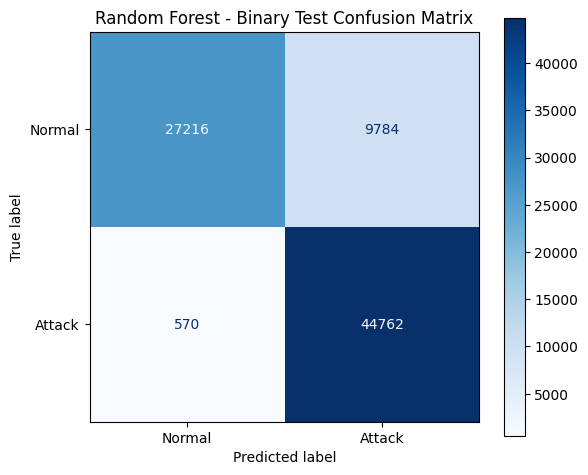

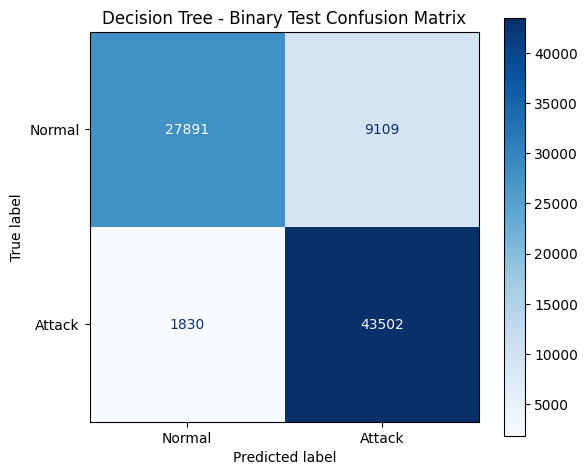

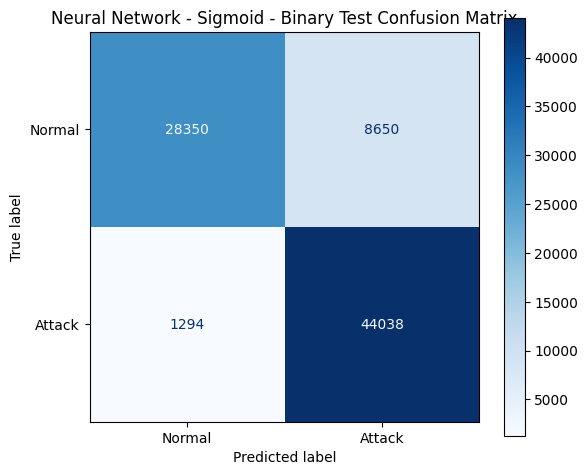

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

binary_test_predictions = {
    "Random Forest": oliver_predictions,
    "Decision Tree": dt_predictions,
    "Neural Network - Sigmoid": nn_binary_predictions
}

for name, y_pred in binary_test_predictions.items():
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test_bin,
        y_pred,
        labels=[0, 1],
        display_labels=["Normal", "Attack"],
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"{name} - Binary Test Confusion Matrix")

    plt.tight_layout()
    plt.show()


Generating normalized confusion matrices for the two multiclass classification models. Showing how accuratly each traffic category is classified and which categories are most frequently mistaken.

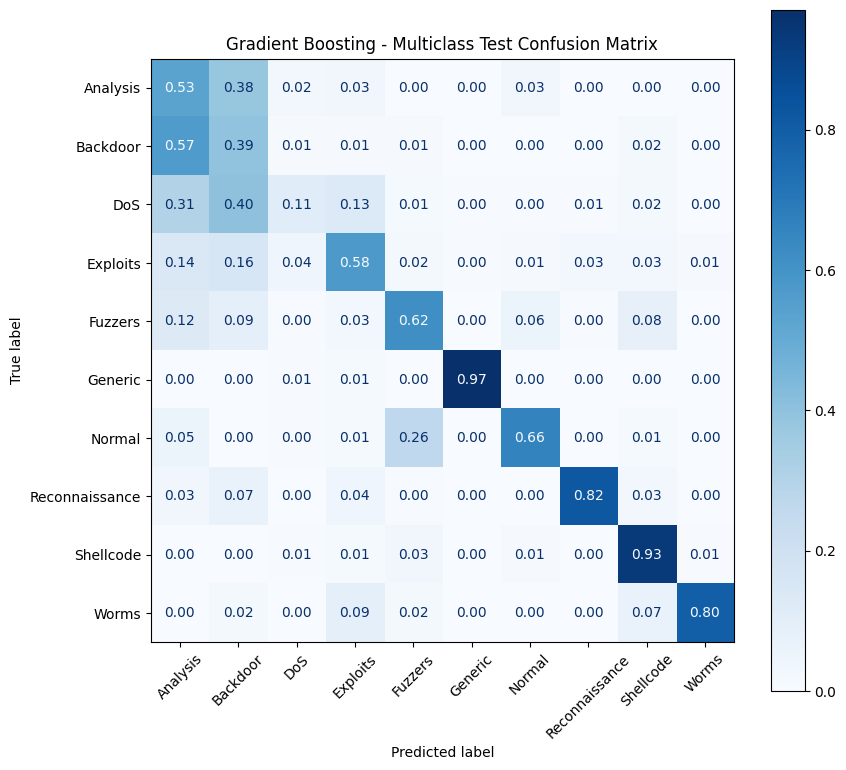

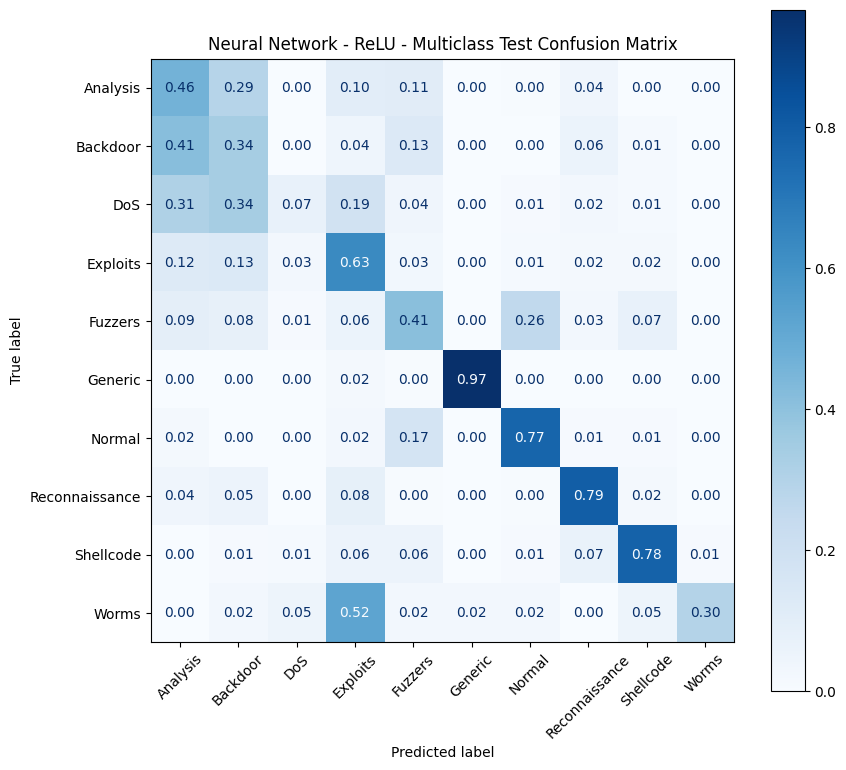

In [ ]:
multiclass_test_predictions = {
    "Gradient Boosting": gb_predictions,
    "Neural Network - ReLU": nn_multi_predictions
}

class_names = le.classes_
class_ids = list(range(len(class_names)))

for name, y_pred in multiclass_test_predictions.items():
    fig, ax = plt.subplots(figsize=(9, 8))

    ConfusionMatrixDisplay.from_predictions(
        y_test_mc,
        y_pred,
        labels=class_ids,
        display_labels=class_names,
        normalize="true",
        cmap="Blues",
        values_format=".2f",
        xticks_rotation=45,
        ax=ax
    )

    ax.set_title(f"{name} - Multiclass Test Confusion Matrix")

    plt.tight_layout()
    plt.show()


Calculating and comparing the F1-scores for the two multiclass classification models for each of the ten traffic categories. Showing the results in a DataFrame.

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

class_names = le.classes_
class_ids = list(range(len(class_names)))

def get_class_results(y_pred):
    report = classification_report(
        y_test_mc,
        y_pred,
        labels=class_ids,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    return pd.DataFrame(report).T.loc[
        class_names,
        ["precision", "recall", "f1-score", "support"]
    ]

comparison_classes = pd.DataFrame({
    name: get_class_results(y_pred)["f1-score"]
    for name, y_pred in multiclass_test_predictions.items()
})

print("PER-CLASS F1-SCORE COMPARISON")
display(comparison_classes.round(3))


PER-CLASS F1-SCORE COMPARISON


,Gradient Boosting,Neural Network - ReLU
Analysis,0.104,0.117
Backdoor,0.087,0.086
DoS,0.172,0.118
Exploits,0.670,0.670
Fuzzers,0.379,0.320
Generic,0.983,0.980
Normal,0.788,0.845
Reconnaissance,0.851,0.775
Shellcode,0.309,0.321
Worms,0.311,0.168


Creating a bar chart comparing F1-scores for the multiclass models for the ten different traffic categories.

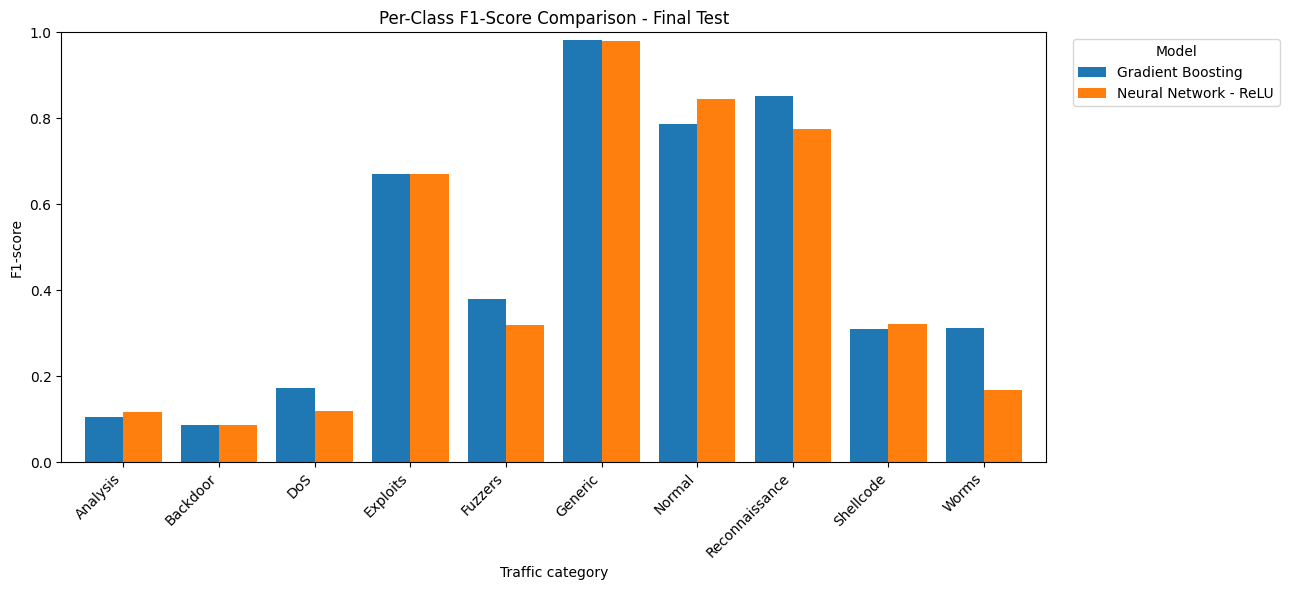

In [ ]:
import matplotlib.pyplot as plt

ax = comparison_classes.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Per-Class F1-Score Comparison - Final Test")
ax.set_xlabel("Traffic category")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1)

ax.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
